# EXPT NO: 7 – GENERATE SYNTHETIC IMAGES USING GAN

**Student Roll No:** 24BAD108  


## PART A – DATASET PREPARATION AND IMAGE PREPROCESSING



In [1]:
# Cell 1: Import Libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [2]:
# Cell 2: Load MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images :", x_test.shape)
print("Image size     :", x_train.shape[1:])


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images : (10000, 28, 28)
Image size     : (28, 28)


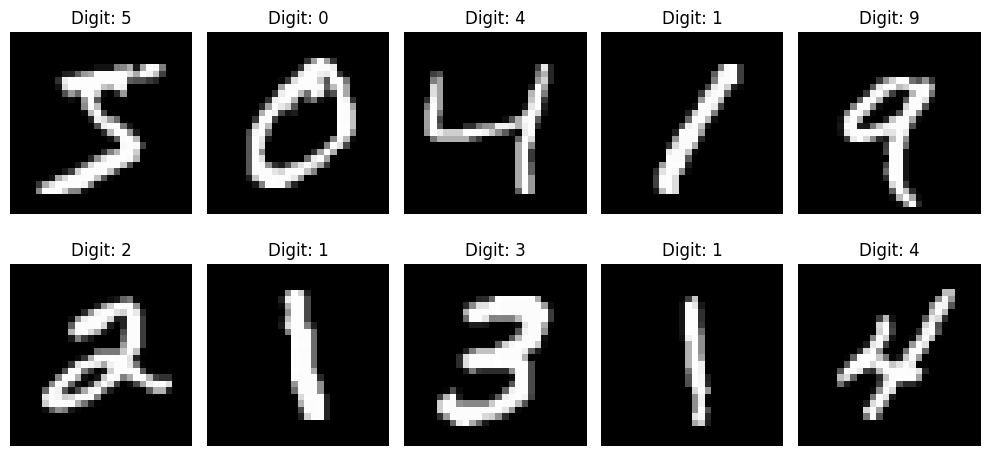

In [3]:
# Cell 3: Display sample real images
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [4]:
# Cell 4: Preprocess images
NUM_IMAGES = 10000

images = x_train[:NUM_IMAGES].astype("float32")
images = (images - 127.5) / 127.5
images = np.expand_dims(images, axis=-1)

print("Preprocessed shape:", images.shape)
print("Range:", images.min(), "to", images.max())


Preprocessed shape: (10000, 28, 28, 1)
Range: -1.0 to 1.0


In [5]:
# Cell 5: Create TensorFlow data pipeline
BATCH_SIZE = 128
BUFFER_SIZE = 10000

train_dataset = (
    tf.data.Dataset.from_tensor_slices(images)
    .shuffle(BUFFER_SIZE, seed=42)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Batch size:", BATCH_SIZE)


Batch size: 128


## PART B – IMPLEMENTING THE GENERATOR




In [6]:
# Cell 6: Generator
LATENT_DIM = 100

generator = models.Sequential([
    layers.Input(shape=(LATENT_DIM,)),
    layers.Dense(7 * 7 * 128, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Reshape((7, 7, 128)),

    layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(32, 5, strides=2, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(1, 5, padding="same", activation="tanh")
])

generator.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        51,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           801 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 909,473 (3.47 MB)

 Trainable params: 896,737 (3.42 MB)

 Non-trainable params: 12,736 (49.75 KB)

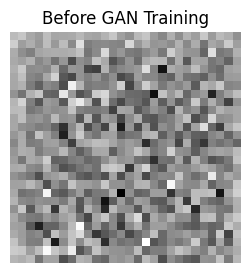

In [7]:
# Cell 7: Generate image before training
noise = tf.random.normal([1, LATENT_DIM])
generated = generator(noise, training=False)

plt.figure(figsize=(3, 3))
plt.imshow(generated[0, :, :, 0] * 0.5 + 0.5, cmap="gray")
plt.title("Before GAN Training")
plt.axis("off")
plt.show()


## PART C – IMPLEMENTING THE DISCRIMINATOR AND GAN MODEL


In [8]:
# Cell 8: Discriminator
discriminator = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 5, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(128, 5, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
])

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002, beta_1=0.5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

discriminator.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Cell 9: Combined GAN model
discriminator.trainable = False

gan_model = models.Sequential([
    generator,
    discriminator
])

gan_model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

gan_model.summary()

# Re-enable discriminator for the custom training loop
discriminator.trainable = True


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 28, 28, 1)      │       909,473 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 1)              │       212,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,122,338 (4.28 MB)

 Trainable params: 896,737 (3.42 MB)

 Non-trainable params: 225,601 (881.25 KB)

## PART D – GAN TRAINING AND SYNTHETIC IMAGE GENERATION




In [10]:
# Cell 10: Loss functions and optimizers
cross_entropy = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

print("GAN training setup complete.")


GAN training setup complete.


In [11]:
# Cell 11: Training step
@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = generator_loss(fake_output)
        d_loss = discriminator_loss(real_output, fake_output)

    g_gradients = gt.gradient(g_loss, generator.trainable_variables)
    d_gradients = dt.gradient(d_loss, discriminator.trainable_variables)

    g_optimizer.apply_gradients(zip(g_gradients, generator.trainable_variables))
    d_optimizer.apply_gradients(zip(d_gradients, discriminator.trainable_variables))

    return g_loss, d_loss


In [12]:
# Cell 12: Save generated image grid
os.makedirs("generated_images", exist_ok=True)

seed = tf.random.normal([16, LATENT_DIM])

def save_generated_images(epoch):
    predictions = generator(seed, training=False)
    predictions = (predictions + 1) / 2.0

    plt.figure(figsize=(8, 8))
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0], cmap="gray")
        plt.axis("off")

    plt.suptitle(f"Generated Images - Epoch {epoch}")
    path = f"generated_images/epoch_{epoch:02d}.png"
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", path)


Epoch 1/5 | Generator Loss: 0.6789 | Discriminator Loss: 1.2508


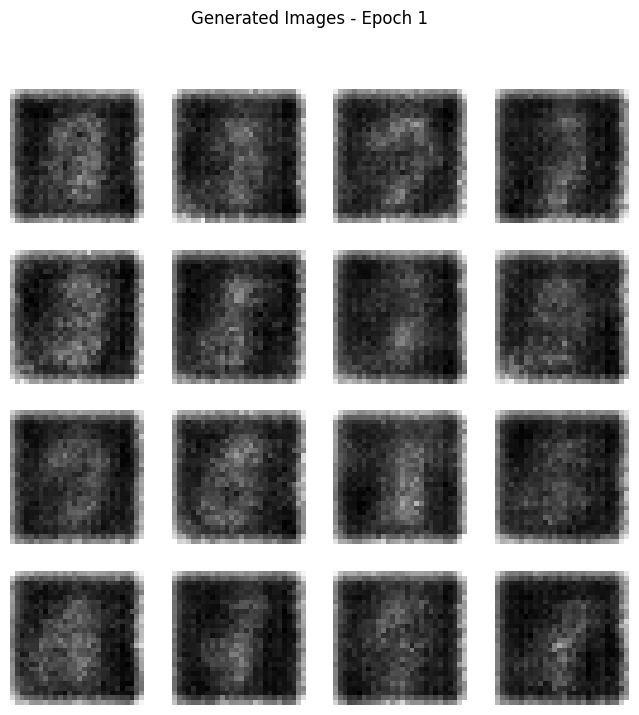

Saved: generated_images/epoch_01.png
Epoch 2/5 | Generator Loss: 0.6978 | Discriminator Loss: 1.3540


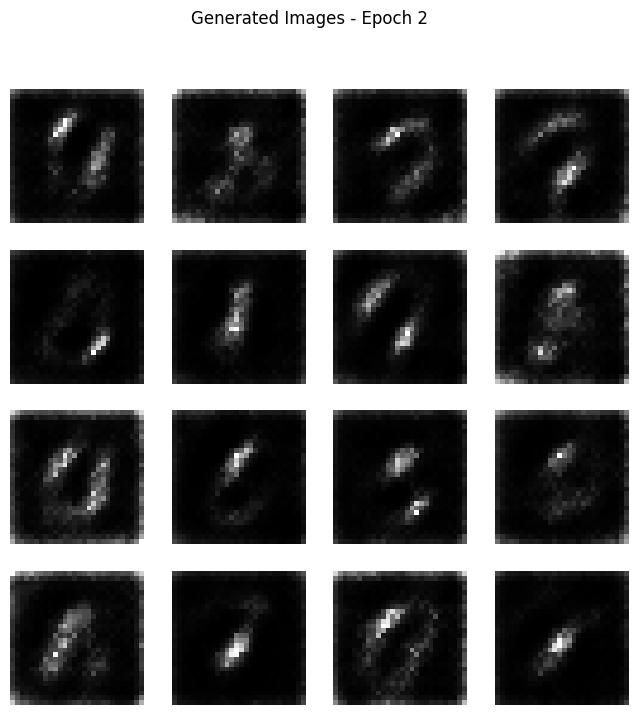

Saved: generated_images/epoch_02.png
Epoch 3/5 | Generator Loss: 0.6974 | Discriminator Loss: 1.3858


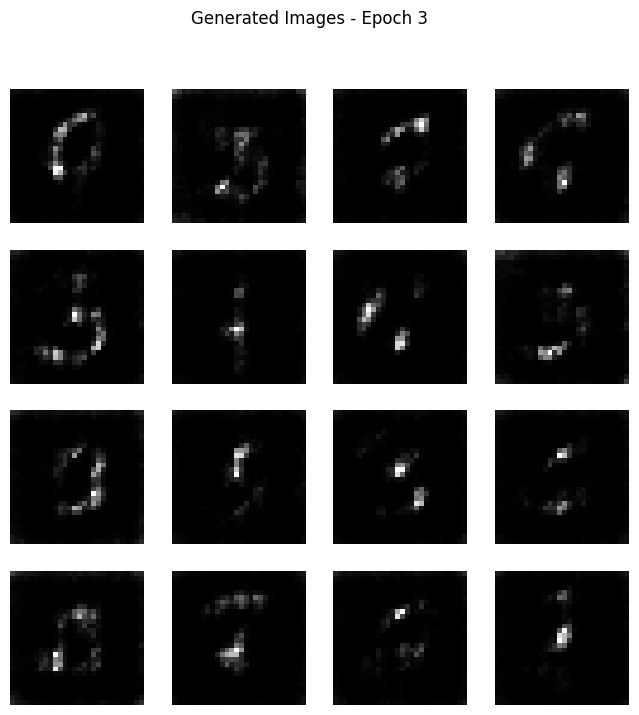

Saved: generated_images/epoch_03.png
Epoch 4/5 | Generator Loss: 0.7030 | Discriminator Loss: 1.3782


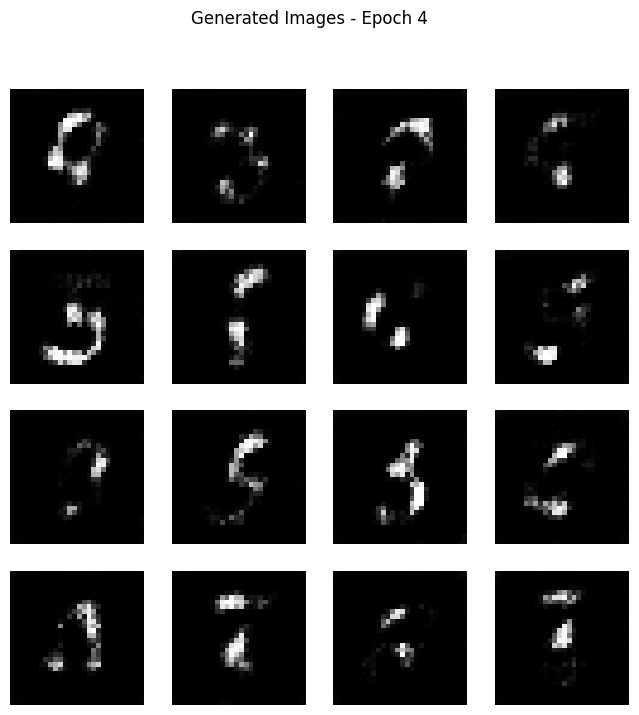

Saved: generated_images/epoch_04.png
Epoch 5/5 | Generator Loss: 0.7197 | Discriminator Loss: 1.3628


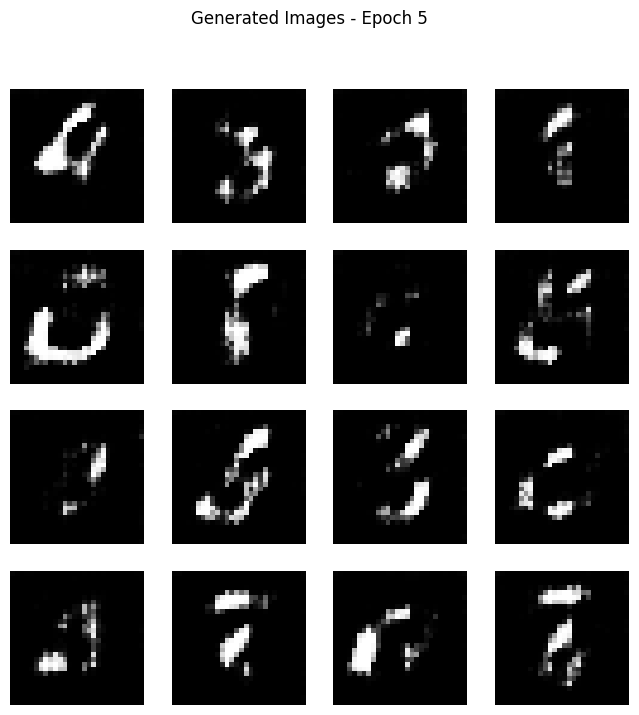

Saved: generated_images/epoch_05.png


In [13]:
# Cell 13: Train GAN
EPOCHS = 5

generator_losses = []
discriminator_losses = []

for epoch in range(1, EPOCHS + 1):
    g_epoch = []
    d_epoch = []

    for real_batch in train_dataset:
        g_loss, d_loss = train_step(real_batch)
        g_epoch.append(float(g_loss))
        d_epoch.append(float(d_loss))

    g_avg = np.mean(g_epoch)
    d_avg = np.mean(d_epoch)

    generator_losses.append(g_avg)
    discriminator_losses.append(d_avg)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Generator Loss: {g_avg:.4f} | "
        f"Discriminator Loss: {d_avg:.4f}"
    )

    save_generated_images(epoch)


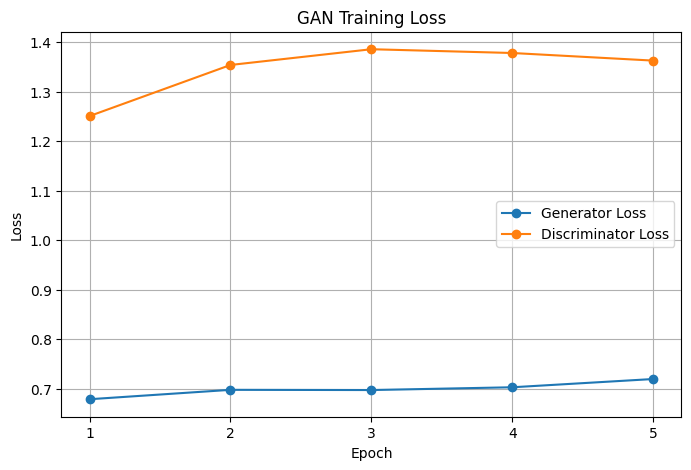

In [14]:
# Cell 14: Plot generator and discriminator losses
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), generator_losses, marker="o", label="Generator Loss")
plt.plot(range(1, EPOCHS + 1), discriminator_losses, marker="o", label="Discriminator Loss")
plt.title("GAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.show()


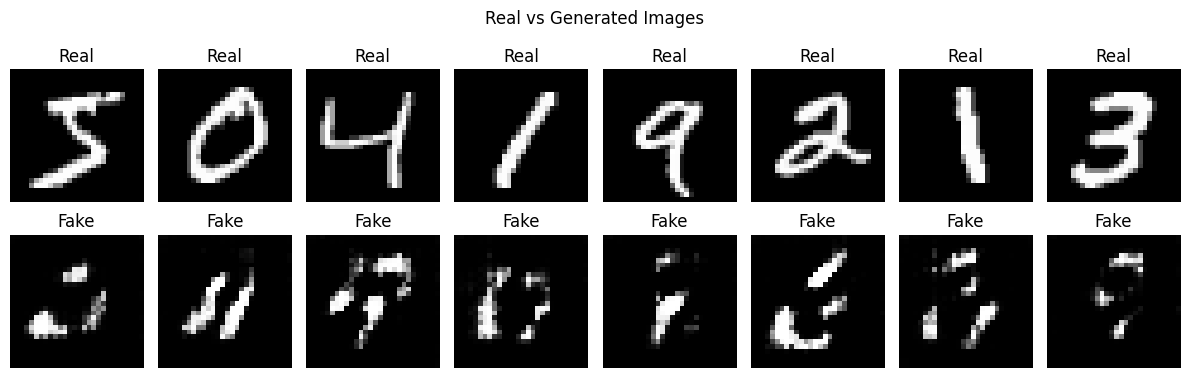

In [15]:
# Cell 15: Compare real and generated images
final_noise = tf.random.normal([8, LATENT_DIM])
final_images = generator(final_noise, training=False)
final_images = (final_images + 1) / 2.0

plt.figure(figsize=(12, 4))

for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow((images[i] + 1) / 2.0, cmap="gray")
    plt.title("Real")
    plt.axis("off")

    plt.subplot(2, 8, i + 9)
    plt.imshow(final_images[i, :, :, 0], cmap="gray")
    plt.title("Fake")
    plt.axis("off")

plt.suptitle("Real vs Generated Images")
plt.tight_layout()
plt.show()


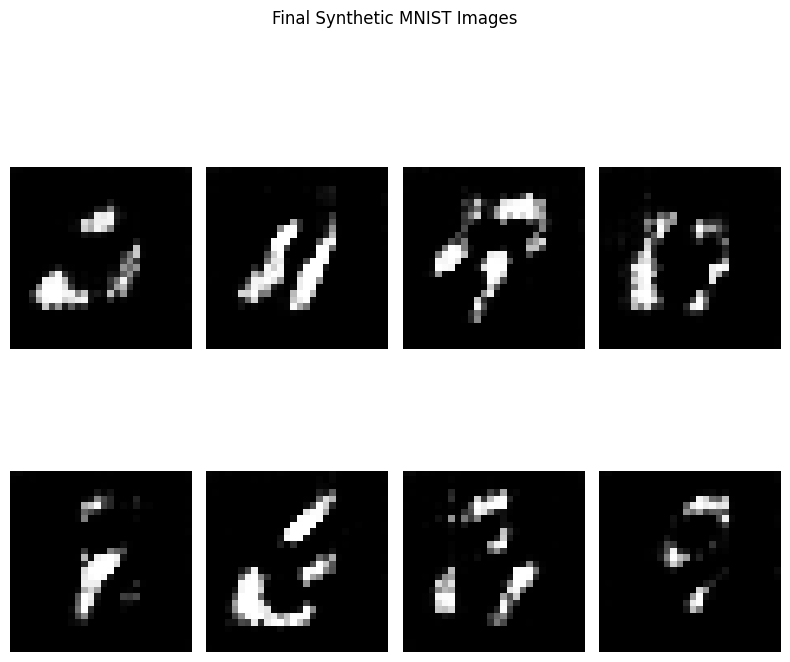

Saved: generated_images/final_generated_images.png


In [16]:
# Cell 16: Save final generated images
final_path = "generated_images/final_generated_images.png"

plt.figure(figsize=(8, 8))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(final_images[i, :, :, 0], cmap="gray")
    plt.axis("off")

plt.suptitle("Final Synthetic MNIST Images")
plt.tight_layout()
plt.savefig(final_path, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", final_path)


In [17]:
# Cell 17: Save trained models
generator.save("mnist_gan_generator.keras")
discriminator.save("mnist_gan_discriminator.keras")

print("Generator saved: mnist_gan_generator.keras")
print("Discriminator saved: mnist_gan_discriminator.keras")


Generator saved: mnist_gan_generator.keras
Discriminator saved: mnist_gan_discriminator.keras
